# Four Coupled Transmons: VQE, VQD and Parameter Comparisons

**Aim:** Calculate the lowest collective transition frequency of four coupled transmons:

$$f_{01}=\frac{E_1-E_0}{h}.$$

### What the notebook does

- Converts circuit inputs into effective capacitance, charging energy and Josephson energy.
- Builds the coupled Hamiltonian and uses **VQE** to find the ground state and **VQD** to find the first excited state.
- Validates the energies and transition frequency against classical diagonalization.
- Compares initialization, charge cutoff, retained levels, optimizers, ansatz size and deflation penalty using accuracy and runtime graphs.

### Main assumptions

- **Identical transmons:** each has $L_J=10\,\mathrm{nH}$ and an uncoupled linear frequency of $5.21015\,\mathrm{GHz}$, implying $C_{\mathrm{eff}}\approx93.31\,\mathrm{fF}$.
- **Effective ring coupling:** neighbouring sites interact through $g_{ij}\hat n_i\hat n_j$, with illustrative coefficients $g_{ij}=0.10\,\mathrm{GHz}$. Interconnect resonator modes are not explicitly included.
- **Finite model:** zero offset charges; charge states $n_i=-7,\ldots,7$. The quantum circuits retain four eigenlevels per transmon, giving 256 states on eight qubits.
- **Ideal simulation:** noiseless statevector calculations, with analytic simulator gradients for L-BFGS-B. Reported runtimes describe local classical simulation.

**Scope:** Results validate the numerical method for this effective model. Predicting the physical device requires calibrated capacitances and couplings.

In [1]:
# %pip install qiskit==2.2.3 numpy==2.3.4 scipy==1.16.3 matplotlib==3.10.7
# Tested with Python 3.14.0 and the versions above.
from pathlib import Path
from time import perf_counter
import csv
import json
import platform
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import scipy.sparse as sp
from scipy.constants import e as electron_charge, h as planck_h
from scipy.linalg import eigh
from scipy.optimize import minimize
from scipy.sparse.linalg import eigsh
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.primitives import StatevectorEstimator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

### 3.1 Step 1: Map the problem to quantum circuits and operators

#### Initial physical parameters and effective capacitance

The linearized Josephson oscillator obeys

$$C_{\mathrm{eff},i}=\frac{1}{L_{J,i}(2\pi f_{\mathrm{lin},i})^2},\qquad
\frac{E_{C,i}}h=\frac{e^2}{2hC_{\mathrm{eff},i}},\qquad
\frac{E_{J,i}}h=\frac{(\hbar/2e)^2}{hL_{J,i}}.$$

Inductance alone does not determine capacitance. Here the supplied linear frequency supplies the second piece of information. If a supplied frequency is already a nonlinear $f_{01}$, this conversion must be replaced by a nonlinear spectrum fit.

All Hamiltonian entries and the variables `E_C`, `E_J`, and `beta` are energies **divided by $h$**, in GHz. Consequently, a difference of their eigenvalues is directly a frequency in GHz. Offset charges are fixed at $n_{g,i}=0$.

Expect $C_{\mathrm{eff}}\simeq93.3125$ fF, $E_C/h\simeq0.207585$ GHz, $E_J/h\simeq16.3462$ GHz and $E_J/E_C\simeq78.74$ at every site. The quadratic charging form is checked to be positive. The 50 kHz study target is an adjustable demonstration tolerance, not an experimentally established uncertainty.

In [2]:
# Demonstration inputs copied from the single-transmon circuit for each site.
# Supply uncoupled local frequencies, rather than four collective mode frequencies.
L_J_nH = np.full(4, 10.0)           # Junction inductances [nH].
f_linear_GHz = np.full(4, 5.21015)  # Local linear frequencies [GHz].
N = 7                             # Charge cutoff per island [integer].
local_levels = 4                   # Retained local eigenlevels [integer].
edges = [(0, 1, 0.10), (1, 2, 0.10), (2, 3, 0.10), (3, 0, 0.10)]
# Edge coefficients multiply n_i*n_j and are illustrative [GHz].
seed = 42
baseline_maxfun = 1000
study_budget = 600                 # Maximum energy calls per state.
study_seeds = [11, 22, 33]
transition_target_khz = 50.0        # Presentation accuracy target [kHz].
SAVE_FIGURES = False
SAVE_DATA = False

assert L_J_nH.shape == f_linear_GHz.shape == (4,)
assert np.all(np.isfinite(L_J_nH)) and np.all(L_J_nH > 0)
assert np.all(np.isfinite(f_linear_GHz)) and np.all(f_linear_GHz > 0)
assert isinstance(N, int) and N >= 2
assert local_levels == 4
# Both L_J and the linear frequency are needed to infer total modal loading.
L_J = L_J_nH * 1e-9
C_effective = 1 / (L_J * (2 * np.pi * f_linear_GHz * 1e9)**2)  # [F].
E_C = electron_charge**2 / (2 * C_effective * planck_h) / 1e9  # [GHz].
E_J = (planck_h / (4 * np.pi * electron_charge))**2 / (L_J * planck_h) / 1e9
assert np.allclose(np.sqrt(8 * E_J * E_C), f_linear_GHz, atol=1e-10)
K = np.diag(4 * E_C)
for i, j, g in edges:
    assert 0 <= i < 4 and 0 <= j < 4 and i != j and np.isfinite(g)
    K[i, j] += g / 2
    K[j, i] += g / 2
assert np.linalg.eigvalsh(K)[0] > 0
print("Effective capacitances [fF]:", C_effective * 1e15)
print("E_C/h [GHz]:", E_C)
print("E_J/h [GHz]:", E_J)
print("E_J/E_C:", E_J / E_C)

Effective capacitances [fF]: [93.31249669 93.31249669 93.31249669 93.31249669]
E_C/h [GHz]: [0.20758451 0.20758451 0.20758451 0.20758451]
E_J/h [GHz]: [16.34615128 16.34615128 16.34615128 16.34615128]
E_J/E_C: [78.74456011 78.74456011 78.74456011 78.74456011]


#### Charge Hamiltonian, local projection and Pauli reconstruction

In frequency units, the physical model is

$$\frac{H}{h}=\sum_{i=1}^4\left[4\frac{E_{C,i}}h\hat n_i^2-
\frac{E_{J,i}}h\cos\hat\phi_i\right]
+\sum_{(i,j)\in\mathcal E}g_{ij}\hat n_i\hat n_j.$$

- The charging term is the electrostatic cost of excess Cooper-pair number. It is diagonal in the charge basis.
- Josephson tunnelling changes the island charge by one Cooper pair: $\cos\phi=(1/2)\sum_n(|n\rangle\langle n+1|+|n+1\rangle\langle n|)$. It gives nearest-neighbour charge matrix elements $-E_J/(2h)$.
- The coupling term correlates charge fluctuations on connected islands. Its sign and coefficient belong to the effective circuit model.

With $N=7$, each island has 15 charge states and the physical sparse matrix has dimension $15^4=50\,625$. Site 1 is the least-significant tensor factor, consistent with Qiskit ordering.

For the circuit, diagonalize each isolated charge Hamiltonian, retain its four lowest eigenlevels and project $Q_i$ to $V_i^\mathsf{T}Q_iV_i$. Each local level $0,1,2,3$ occupies two qubits, so every one of the eight-qubit computational states is physical in the projected model. There is no padding penalty to tune. A direct charge encoding would require four qubits per island with unused states; it is not used for this simulation.

The resulting matrix `A` is written as $A=\sum_P c_P P$ with Qiskit's `SparsePauliOp`. An assertion checks that its Pauli sum reproduces `A`. Expect 77 Pauli terms with these defaults.

In [3]:
def local_hamiltonian(ec, ej, cutoff):
    """Return a zero-offset charge Hamiltonian [GHz] and charge operator."""
    # Charge eigenstates make the electrostatic cost diagonal.
    n = np.arange(-cutoff, cutoff + 1)
    hop = np.full(n.size - 1, -ej / 2)  # Cooper-pair tunnelling [GHz].
    return (
        sp.diags([hop, 4 * ec * n**2, hop], [-1, 0, 1], format="csr"),
        sp.diags(n, format="csr"),
    )


def tensor_sparse(operators):
    """Use site 0 as the least-significant tensor factor."""
    result = sp.csr_matrix([[1.0]])
    for operator in reversed(operators):
        result = sp.kron(result, operator, format="csr")
    return result


def build_hamiltonian(local_h, local_q, coupling_scale=1.0):
    """Assemble the four local terms and effective charge couplings [GHz]."""
    size = local_h[0].shape[0]
    identity = sp.eye(size, format="csr")
    result = sp.csr_matrix((size**4, size**4))
    for site, h_local in enumerate(local_h):
        operators = [identity] * 4
        operators[site] = h_local
        result += tensor_sparse(operators)
    # Products of charge operators couple fluctuations on connected islands.
    for i, j, g in edges:
        operators = [identity] * 4
        operators[i], operators[j] = local_q[i], local_q[j]
        result += coupling_scale * g * tensor_sparse(operators)
    return result


def charge_reference(cutoff, repeats=1, coupling_scale=1.0):
    """Build the charge model and time its two lowest sparse eigenpairs."""
    started = perf_counter()
    models = [local_hamiltonian(ec, ej, cutoff) for ec, ej in zip(E_C, E_J)]
    matrix = build_hamiltonian(
        [m[0] for m in models], [m[1] for m in models], coupling_scale
    )
    build_seconds = perf_counter() - started
    times = []
    for repeat in range(repeats):
        started = perf_counter()
        values, vectors = eigsh(
            matrix, k=2, which="SA", tol=1e-11,
            v0=np.random.default_rng(seed + repeat).normal(size=matrix.shape[0]),
        )
        times.append(perf_counter() - started)
    order = np.argsort(values)
    values, vectors = values[order], vectors[:, order]
    residuals = np.linalg.norm(matrix @ vectors - vectors * values, axis=0)
    assert np.max(residuals) < 1e-7
    return dict(matrix=matrix, energies=values, vectors=vectors, seconds=times,
                build_seconds=build_seconds, residuals=residuals)


model_start = perf_counter()
local_h, local_q, local_e, local_v = [], [], [], []
for ec, ej in zip(E_C, E_J):
    h_local, charge = local_hamiltonian(ec, ej, N)
    values, vectors = np.linalg.eigh(h_local.toarray())
    local_h.append(h_local)
    local_q.append(charge)
    local_e.append(values)
    local_v.append(vectors)
H = build_hamiltonian(local_h, local_q)
# Retain physical local eigenlevels to reduce the circuit from 16 to 8 qubits.
projected_q = [
    sp.csr_matrix(v[:, :local_levels].T @ q @ v[:, :local_levels])
    for v, q in zip(local_v, local_q)
]
A = build_hamiltonian(
    [sp.diags(e[:local_levels]) for e in local_e], projected_q
).toarray()
num_qubits = 8
# Four levels per site fill the qubit space exactly, so padding is absent.
hamiltonian = SparsePauliOp.from_operator(Operator(A), atol=1e-11, rtol=0)
assert np.allclose(hamiltonian.to_matrix(), A, atol=1e-9, rtol=0)
model_seconds = perf_counter() - model_start
print(f"Charge dimension: {H.shape[0]:,}; projected dimension: {len(A)}")
print(f"VQE/VQD qubits: {num_qubits}; Pauli terms: {len(hamiltonian)}")

Charge dimension: 50,625; projected dimension: 256
VQE/VQD qubits: 8; Pauli terms: 77


/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_67278/477346295.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  sp.diags(n, format="csr"),


#### Exact reference energies

Find the two lowest eigenpairs of the full charge matrix with a sparse eigensolver and check their residuals. Separately, use NumPy to diagonalize the complete 256-state projected matrix. These reference solutions assess the algorithm; the full coupled eigenvectors are not used to initialize its circuits.

At zero offset charge, the local eigenstates alternate charge-reflection parity. The coupling preserves **total** parity. The lowest state is even and the first excited state is odd for these defaults; both remain in `A`.

Expect an isolated-transmon quantum transition near 4.99328 GHz and a lowest collective transition near 4.68324 GHz. They differ because of the assumed coupling. The four-level projection shifts this transition by about 12.53 kHz at $N=7$.

[SciPy sparse eigensolver documentation](https://docs.scipy.org/doc/scipy-1.16.1/reference/generated/scipy.sparse.linalg.eigsh.html)

In [4]:
classical_charge = charge_reference(N, repeats=3)
charge_energies = classical_charge["energies"]
f01_charge = float(charge_energies[1] - charge_energies[0])
# This independent exact answer is for validation, not parameter selection.
projected_energies, projected_vectors = np.linalg.eigh(A)
f01_projected = float(projected_energies[1] - projected_energies[0])
labels = np.array([[(k >> (2 * i)) & 3 for i in range(4)] for k in range(256)])
parity = (-1.0)**np.sum(labels, axis=1)
for index, expected in ((0, 1), (1, -1)):
    assert np.isclose(
        np.sum(parity * projected_vectors[:, index]**2), expected, atol=1e-9
    )
print(f"Isolated local transitions [GHz]: {[e[1]-e[0] for e in local_e]}")
print(f"Full charge collective f01: {f01_charge:.12f} GHz")
print(f"Projected collective f01:   {f01_projected:.12f} GHz")
print(f"Projection frequency shift: {1e6*(f01_projected-f01_charge):.3f} kHz")

/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_67278/477346295.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  sp.diags(n, format="csr"),


Isolated local transitions [GHz]: [np.float64(4.993281640359472), np.float64(4.993281640359472), np.float64(4.993281640359472), np.float64(4.993281640359472)]
Full charge collective f01: 4.683236766541 GHz
Projected collective f01:   4.683249295297 GHz
Projection frequency shift: 12.529 kHz


#### Ansatz and first-excited reference state

Prepare states as

$$|\psi_s(\boldsymbol\theta)\rangle=W_s
\prod_k e^{-i\theta_kP_k/2}|0\cdots0\rangle.$$

For the ground state, $W_0=I$, and zero angles give a product of isolated ground states. For the excited state, $W_1$ prepares the lowest collective combination in the **four-dimensional one-excitation block**. This small classical reference calculation resolves the identical-site degeneracy; it is not a diagonalization of the complete interacting system. Further optimization incorporates higher-level components and dressing.

Each $P_k$ contains one $Y$, with $X$ on its other selected bits. The resulting rotations preserve real amplitudes, appropriate because this Hamiltonian is real. The 255 masks supply independent real directions around the reference. The fixed reference circuit is applied after the variable rotations, which makes these directions useful for both states.

This is an accuracy-oriented ansatz, with substantial gate cost. It is not claimed to be a shallow hardware-ready circuit. The restricted comparison retains masks exciting at most two sites and has 66 angles. Expect these parameter counts to print.

[Qiskit PauliEvolutionGate documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.circuit.library.PauliEvolutionGate)

In [5]:
# Solve only the four-dimensional one-excitation block for a reference circuit.
one_excitation = np.array([1 << (2 * site) for site in range(4)])
_, mode_vectors = np.linalg.eigh(A[np.ix_(one_excitation, one_excitation)])
weights = mode_vectors[:, 0].copy()
if weights[0] < 0:
    weights *= -1
excited_reference_circuit = QuantumCircuit(num_qubits)
excited_reference_circuit.x(0)
for site in range(1, 4):
    remaining = np.sqrt(weights[0]**2 + np.sum(weights[site + 1:]**2))
    angle = -2 * np.arctan2(weights[site], remaining)
    a, b = 0, 2 * site
    excited_reference_circuit.cx(a, b)
    excited_reference_circuit.cry(angle, b, a)
    excited_reference_circuit.cx(a, b)

reference_unitary = Operator(excited_reference_circuit).data
assert np.max(np.abs(reference_unitary.imag)) < 1e-10
reference_unitary = reference_unitary.real
assert np.allclose(reference_unitary.T @ reference_unitary, np.eye(256), atol=1e-10)
ground_reference_circuit = QuantumCircuit(num_qubits)
identity_reference = np.eye(256)
reference_matrices = [identity_reference, reference_unitary]
frame_matrices = [A, reference_unitary.T @ A @ reference_unitary]

# Real Pauli rotations fit a real Hamiltonian without redundant complex phases.
full_masks = list(range(1, 256))
pair_masks = [k for k in full_masks if np.count_nonzero(labels[k]) <= 2]


def rotation_tables(masks):
    """Precompute the real action of each single-Y Pauli generator."""
    indices = np.arange(256)
    permutations, signs = [], []
    for mask in masks:
        pivot = (mask & -mask).bit_length() - 1
        permutations.append(indices ^ mask)
        signs.append(-(1 - 2 * ((indices >> pivot) & 1)))
    return np.array(permutations), np.array(signs)


def make_ansatz(masks, reference_circuit, prefix):
    """Append a fixed reference unitary after the variable real rotations."""
    circuit = QuantumCircuit(num_qubits)
    parameters = ParameterVector(prefix, len(masks))
    for parameter, mask in zip(parameters, masks):
        bits = [bit for bit in range(num_qubits) if mask & (1 << bit)]
        label = ["I"] * num_qubits
        for bit in bits:
            label[num_qubits - 1 - bit] = "X"
        label[num_qubits - 1 - bits[0]] = "Y"
        circuit.append(
            PauliEvolutionGate(SparsePauliOp("".join(label)), time=parameter / 2),
            range(num_qubits),
        )
    circuit.compose(reference_circuit, inplace=True)
    return circuit


permutations, rotation_signs = rotation_tables(full_masks)
ground_ansatz = make_ansatz(full_masks, ground_reference_circuit, "theta_g")
excited_ansatz = make_ansatz(full_masks, excited_reference_circuit, "theta_e")
print(f"Full ansatz angles per state: {len(full_masks)}")
print(f"Restricted comparison pool: {len(pair_masks)} angles")

Full ansatz angles per state: 255
Restricted comparison pool: 66 angles


### 3.2 Step 2: Optimize for target hardware

#### Define the target, transpile, and apply the observable layout

Follow the supplied local-target workflow with eight qubits, all-to-all connectivity, and `u` and `cx` basis gates. The target connectivity describes the computer implementing the calculation; the ring describes the physical circuit being modelled.

Compile once and apply each circuit's layout to its Pauli observable before taking expectations. Expect gate counts and compilation time. On the tested version, the ground/excited circuits have approximately 614/620 CX gates. These counts motivate the later accuracy-versus-circuit-cost comparison.

In [6]:
backend = GenericBackendV2(
    num_qubits=num_qubits, basis_gates=["u", "cx"], seed=seed, noise_info=False
)
target = backend.target
pm = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=seed
)
compile_start = perf_counter()
ground_isa = pm.run(ground_ansatz)
excited_isa = pm.run(excited_ansatz)
compile_seconds = perf_counter() - compile_start
# The observable must follow the same wire layout as the transpiled circuit.
ground_hamiltonian_isa = hamiltonian.apply_layout(ground_isa.layout)
excited_hamiltonian_isa = hamiltonian.apply_layout(excited_isa.layout)
print("Ground gate counts:", dict(ground_isa.count_ops()))
print("Excited gate counts:", dict(excited_isa.count_ops()))
print(f"Compilation: {compile_seconds:.3f} s")

Ground gate counts: {'u': 842, 'cx': 614}
Excited gate counts: {'u': 854, 'cx': 620}
Compilation: 0.400 s


### 3.3 Step 3: Execute on target hardware

#### 3.3.1 Reporting out values: energy, overlap and gradients

VQE minimizes $E(\boldsymbol\theta)=\langle\psi|H/h|\psi\rangle$. VQD minimizes

$$F_1(\boldsymbol\theta)=E(\boldsymbol\theta)+\beta
|\langle\widetilde\psi_0|\psi(\boldsymbol\theta)\rangle|^2.$$

The second term discourages rediscovery of the ground state. **The physical excited energy is $E$, not the penalized cost $F_1$.** Transition frequencies must use the physical energies.

The baseline obtains energy expectations from Qiskit's noiseless `StatevectorEstimator`. A faster real-state kernel computes identical expectations for repeated studies. Assertions check it against logical and transpiled Qiskit circuits at seeded test angles. An adjoint calculation supplies exact classical simulator gradients; selected derivatives are checked by finite differences. This gradient access would require a different measurement procedure on hardware.

Expect the circuit/layout/gradient checks to pass. The overlap is noiseless; an independent compute-uncompute circuit checks it later.

[Original VQD method](https://arxiv.org/abs/1805.08138)

In [7]:
def trial_state(parameters, tables, keep_steps=False):
    """Simulate variable real Pauli rotations before the fixed reference."""
    perms, signs = tables
    state = np.zeros(256)
    state[0] = 1.0
    steps = []
    for angle, permutation, sign in zip(parameters, perms, signs):
        state = np.cos(angle / 2)*state + np.sin(angle / 2)*sign*state[permutation]
        if keep_steps:
            steps.append(state)
    return (state, steps) if keep_steps else state


def state_energy(state, matrix):
    """Return an energy expectation [GHz]."""
    return float(np.einsum("i,ij,j->", state, matrix, state))


def cost_components(parameters, matrix, tables, ground=None, beta=0.0):
    """Return physical energy and squared overlap in the reference frame."""
    state = trial_state(parameters, tables)
    energy = state_energy(state, matrix)
    overlap = 0.0 if ground is None else float((ground @ state)**2)
    return energy + beta*overlap, energy, overlap


def cost_gradient(parameters, matrix, tables, ground=None, beta=0.0):
    """Differentiate the noiseless circuit by propagating an adjoint state."""
    state, steps = trial_state(parameters, tables, keep_steps=True)
    action = matrix @ state
    if ground is not None:
        action += beta*ground*(ground @ state)
    gradient = np.empty(len(parameters))
    perms, signs = tables
    for k in reversed(range(len(parameters))):
        gradient[k] = action @ (signs[k]*steps[k][perms[k]])
        action = (
            np.cos(parameters[k]/2)*action
            - np.sin(parameters[k]/2)*signs[k]*action[perms[k]]
        )
    return gradient


tables = (permutations, rotation_signs)
estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
for stage, circuit, observable in (
    (0, ground_ansatz, ground_hamiltonian_isa),
    (1, excited_ansatz, excited_hamiltonian_isa),
):
    test_angles = np.random.default_rng(seed + stage).normal(0, 0.01, len(full_masks))
    pre_state = trial_state(test_angles, tables)
    physical_state = reference_matrices[stage] @ pre_state
    circuit_state = Statevector.from_instruction(
        circuit.decompose().assign_parameters(test_angles)
    ).data
    assert abs(np.vdot(circuit_state, physical_state))**2 > 1-1e-9
    isa = ground_isa if stage == 0 else excited_isa
    measured = float(estimator.run([(isa, observable, test_angles)]).result()[0].data.evs.item())
    assert np.isclose(measured, state_energy(pre_state, frame_matrices[stage]), atol=1e-8)
    derivative = cost_gradient(test_angles, frame_matrices[stage], tables)
    for k in (0, 15, 200):
        shift = np.zeros(len(full_masks)); shift[k] = 1e-6
        finite = (cost_components(test_angles+shift, frame_matrices[stage], tables)[0]
                  - cost_components(test_angles-shift, frame_matrices[stage], tables)[0]) / 2e-6
        assert np.isclose(derivative[k], finite, atol=2e-7, rtol=1e-5)
print("Circuit, observable layout and analytic-gradient checks passed.")

Circuit, observable layout and analytic-gradient checks passed.


#### Initial parameters and the classical optimizer

Compare four angle strategies: zero-angle reference, a perturbative guess, a small seeded random perturbation, and uniform random angles. The perturbative guess estimates amplitudes from reference-frame Hamiltonian matrix elements, without using full coupled eigenvectors:

$$\theta_k\approx-\frac{2\langle k|A_s|0\rangle}{\langle k|A_s|k\rangle-\langle0|A_s|0\rangle}.$$

The implementation accounts for each rotation's sign, clips large guesses, and adds tiny seeded offsets. For VQD the same estimate includes the overlap penalty.

With an exact ground reference, $\beta>E_1-E_0$ prevents the deflated ground level from remaining lowest. Choose a conservative coefficient using a Gershgorin lower bound on $E_0$ and a two-dimensional Ritz upper bound on $E_1$, rather than inserting the exact gap. An approximate VQE ground state weakens this guarantee, so overlap and transition accuracy are still validated. Expect $\beta\simeq6.7541$ GHz.

The runner records every energy evaluation, physical energy, deflated cost, overlap, elapsed time and termination status. L-BFGS-B uses the verified simulator gradient; Powell and COBYLA use only costs. A shared **energy-call** cap makes budgets explicit, but does not make hardware resource costs equal: gradient calls are recorded separately. Budget-limited results must be judged by accuracy, not treated as converged automatically.

In [8]:
def initial_angles(kind, run_seed, matrix, masks, tables, ground=None, beta=0.0):
    """Initialize in the reference frame without exact coupled eigenvectors."""
    random = np.random.default_rng(run_seed)
    if kind == "Reference":
        return np.zeros(len(masks))
    if kind == "Small random":
        return random.normal(0, 0.03, len(masks))
    if kind == "Uniform random":
        return random.uniform(-np.pi, np.pi, len(masks))
    if kind != "Perturbative":
        raise ValueError(kind)
    vacuum = np.zeros(256); vacuum[0] = 1
    action = matrix @ vacuum
    reference_energy = state_energy(vacuum, matrix)
    if ground is not None:
        action += beta*ground*(ground @ vacuum)
        reference_energy += beta*(ground @ vacuum)**2
    directions = tables[1]*vacuum[tables[0]]
    excited_energies = np.einsum("ki,ij,kj->k", directions, matrix, directions)
    if ground is not None:
        excited_energies += beta*(directions @ ground)**2
    gaps = excited_energies - reference_energy
    angles = np.zeros(len(masks))
    np.divide(-2*(directions @ action), gaps, out=angles, where=gaps > 1e-6)
    return np.clip(angles, -0.2, 0.2) + random.normal(0, 1e-6, len(masks))


class EvaluationBudgetReached(Exception):
    """Stop before exceeding the energy-evaluation cap."""


def optimize_state(stage, method, kind, run_seed, budget, masks=full_masks,
                   ground_state=None, beta=0.0, use_estimator=False,
                   matrix_physical=A, reference_matrix=None):
    """Optimize one state and record physical energies, costs and elapsed time."""
    local_tables = rotation_tables(masks)
    reference = reference_matrices[stage] if reference_matrix is None else reference_matrix
    matrix = matrix_physical if stage == 0 else reference.T @ matrix_physical @ reference
    ground_frame = None if ground_state is None else reference.T @ ground_state
    start_angles = initial_angles(kind, run_seed, matrix, masks, local_tables, ground_frame, beta)
    best_cost = np.inf
    best_parameters = start_angles.copy()
    costs, energies, overlaps, times = [], [], [], []
    gradient_calls = 0
    started = perf_counter()

    def objective(parameters):
        nonlocal best_cost, best_parameters, gradient_calls
        if len(costs) >= budget:
            raise EvaluationBudgetReached
        cost, energy, overlap = cost_components(parameters, matrix, local_tables, ground_frame, beta)
        if use_estimator:
            assert masks == full_masks and matrix_physical is A
            isa = ground_isa if stage == 0 else excited_isa
            observable = ground_hamiltonian_isa if stage == 0 else excited_hamiltonian_isa
            energy = float(estimator.run([(isa, observable, parameters)]).result()[0].data.evs.item())
            cost = energy + beta*overlap
        # Select by optimization cost, never by agreement with exact validation.
        if cost < best_cost:
            best_cost, best_parameters = cost, parameters.copy()
        costs.append(cost); energies.append(energy); overlaps.append(overlap)
        times.append(perf_counter()-started)
        if method == "L-BFGS-B":
            gradient_calls += 1
            return cost, cost_gradient(parameters, matrix, local_tables, ground_frame, beta)
        return cost

    options = {
        "L-BFGS-B": {"maxiter":budget,"maxfun":budget,"ftol":1e-13,"gtol":1e-8,"maxls":40},
        "COBYLA": {"maxiter":budget,"rhobeg":0.05,"tol":1e-6},
        "Powell": {"maxfev":budget,"xtol":1e-5,"ftol":1e-10},
    }[method]
    try:
        result = minimize(objective, start_angles, method=method,
                          jac=True if method == "L-BFGS-B" else None, options=options)
        final_parameters = result.x.copy()
        termination = str(result.message)
        converged = bool(result.success)
    except EvaluationBudgetReached:
        final_parameters = best_parameters.copy()
        termination = "Shared energy-evaluation budget"
        converged = False
    elapsed = perf_counter()-started
    final_state = reference @ trial_state(final_parameters, local_tables)
    return dict(state=final_state, parameters=final_parameters,
                energy=state_energy(final_state, matrix_physical),
                nfev=len(costs), njev=gradient_calls, seconds=elapsed,
                cost=np.array(costs), energy_trace=np.array(energies),
                overlap_trace=np.array(overlaps), times=np.array(times),
                termination=termination, converged=converged)


# Bound the required penalty without inserting the exact coupled gap.
diagonal = np.diag(A)
lower_bound = np.min(diagonal - (np.sum(np.abs(A), axis=1)-abs(diagonal)))
upper_bound = np.linalg.eigvalsh(A[np.ix_([0,1],[0,1])])[-1]
beta = float(1.2*(upper_bound-lower_bound))  # Deflation coefficient [GHz].
print(f"Deflation beta: {beta:.6f} GHz")

Deflation beta: 6.754109 GHz


#### Run the classical optimizer: ground VQE, then first-excited VQD

Use the perturbative start and L-BFGS-B for the baseline. First optimize the ground state, then hold that state fixed in the VQD overlap penalty. The retained state is selected from the optimizer result, or by lowest observed cost when the shared cap interrupts it; exact validation energies are never used to select parameters.

Calculate

$$f_{01}=\frac{E_1-E_0}{h}.$$

Since stored energies already have units of GHz, the code directly subtracts them. Expect $f_{01}\simeq4.6832493$ GHz and negligible ground overlap. Print the absolute error against the full charge calculation and the two-state local optimization time. A frequency error can cancel errors in $E_0$ and $E_1$; the comparison records also retain their separate errors and state fidelities.

In [9]:
ground_run = optimize_state(
    0, "L-BFGS-B", "Perturbative", seed, baseline_maxfun, use_estimator=True
)
excited_run = optimize_state(
    1, "L-BFGS-B", "Perturbative", seed+1, baseline_maxfun,
    ground_state=ground_run["state"], beta=beta, use_estimator=True,
)
E0_vqe, E1_vqd = ground_run["energy"], excited_run["energy"]
# Subtract physical energies; the deflated cost includes an artificial penalty.
f01_vqd = E1_vqd-E0_vqe
squared_overlap = float((ground_run["state"] @ excited_run["state"])**2)
assert E0_vqe >= projected_energies[0]-1e-8
assert squared_overlap < 1e-7
print(f"E0 VQE: {E0_vqe:.12f} GHz; E1 VQD: {E1_vqd:.12f} GHz")
print(f"Lowest collective transition: {f01_vqd:.12f} GHz")
print(f"Error against charge model: {1e6*abs(f01_vqd-f01_charge):.3f} kHz")
print(f"Ground overlap: {squared_overlap:.3e}")
print(f"Qiskit VQE + VQD optimizer time: {ground_run['seconds']+excited_run['seconds']:.3f} s")

E0 VQE: -55.185392569758 GHz; E1 VQD: -50.502143274459 GHz
Lowest collective transition: 4.683249295299 GHz
Error against charge model: 12.529 kHz
Ground overlap: 2.057e-13
Qiskit VQE + VQD optimizer time: 17.500 s


### 3.4 Step 4: Post-process results

#### Validate overlap and restore physical charge amplitudes

Check the squared overlap using the all-zero probability after a compute-uncompute circuit. Then reshape each optimized projected state and apply the retained local charge eigenvectors to recover its physical charge wavefunction. Its full charge expectation must equal the projected expectation.

These checks test both the tensor-factor ordering and projection implementation. They do not establish that four local levels or the finite charge cutoff are sufficient; the comparison sections below tests those approximations separately. Expect both independent reconstruction checks to pass.

In [10]:
# Verify the overlap using the equivalent compute-uncompute circuit.
bound_ground = ground_ansatz.assign_parameters(ground_run["parameters"])
bound_excited = excited_ansatz.assign_parameters(excited_run["parameters"])
overlap_circuit = bound_excited.compose(bound_ground.inverse())
overlap_from_circuit = float(abs(Statevector.from_instruction(
    overlap_circuit.decompose()
).data[0])**2)
assert np.isclose(overlap_from_circuit, squared_overlap, atol=1e-9)

# Restore the full physical charge wavefunctions to validate the local projection.
for result in (ground_run, excited_run):
    tensor_state = result["state"].reshape((4,)*4)
    for site, vectors in enumerate(local_v):
        axis = 3-site
        tensor_state = np.tensordot(vectors[:,:4], tensor_state, axes=(1,axis))
        tensor_state = np.moveaxis(tensor_state, 0, axis)
    physical_state = tensor_state.ravel()
    restored_energy = float(np.vdot(physical_state, H @ physical_state).real)
    assert np.isclose(restored_energy, result["energy"], atol=1e-8)
print("Physical charge reconstruction and compute-uncompute overlap passed.")

Physical charge reconstruction and compute-uncompute overlap passed.


#### Figure 1 — VQE/VQD convergence and ground-state rejection

Display the ground-state energy, the excited state's physical energy and deflated cost, and its squared overlap with the optimized ground state. Horizontal lines show the projected exact eigenvalues.

The horizontal axis counts **energy evaluations**, including optimizer trial points, rather than accepted optimizer iterations. Trial costs need not decrease at every call. For the good baseline reference, physical energy and deflated cost nearly coincide because overlap is already small. Figure 10 in the comparison sections below tests starts that can collapse without a sufficient penalty.

Expect both states to reach their projected references and the final squared ground overlap to be around $10^{-13}$. Figures only display inline unless saving is explicitly enabled.

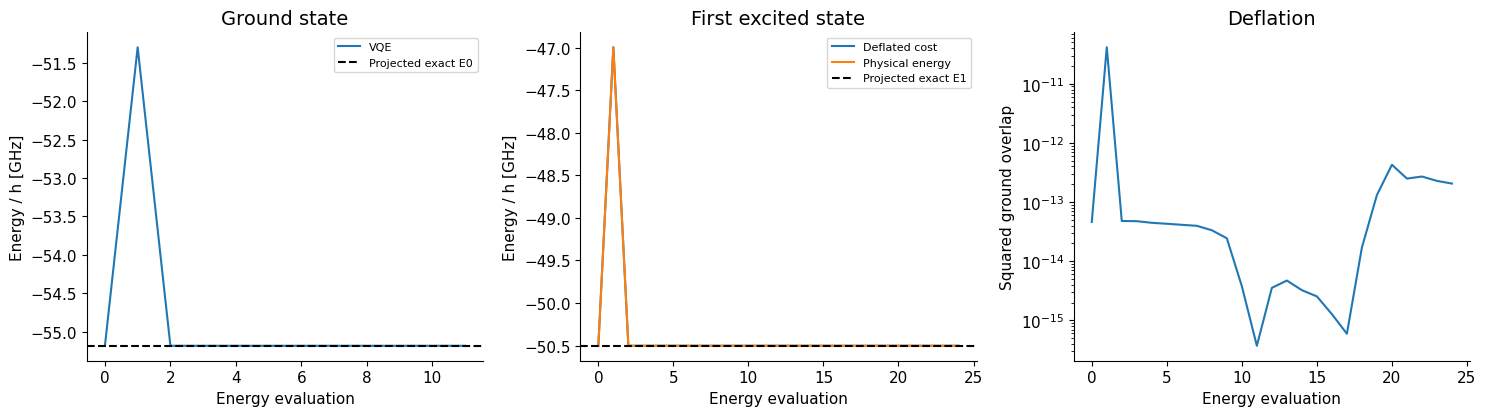

In [11]:
figure_names = []
plt.rcParams.update({"font.size":11,"axes.titlesize":14,"axes.labelsize":11,
                     "axes.spines.top":False,"axes.spines.right":False})
plot_floor = 1e-6  # Display-only floor for logarithmic gaps [kHz].


def show_figure(fig, name):
    """Display inline and export only when the user enables SAVE_FIGURES."""
    fig.tight_layout()
    if name not in figure_names:
        figure_names.append(name)
    if SAVE_FIGURES:
        folder = Path("four_transmon_vqd_figures")
        folder.mkdir(exist_ok=True)
        for extension in ("png","svg"):
            fig.savefig(folder/f"{name}.{extension}",dpi=240,bbox_inches="tight")
    plt.show()


fig, axes = plt.subplots(1,3,figsize=(15,4.3))
axes[0].plot(ground_run["energy_trace"],label="VQE")
axes[0].axhline(projected_energies[0],ls="--",color="black",label="Projected exact E0")
axes[0].set(xlabel="Energy evaluation",ylabel="Energy / h [GHz]",title="Ground state")
axes[1].plot(excited_run["cost"],label="Deflated cost")
axes[1].plot(excited_run["energy_trace"],label="Physical energy")
axes[1].axhline(projected_energies[1],ls="--",color="black",label="Projected exact E1")
axes[1].set(xlabel="Energy evaluation",ylabel="Energy / h [GHz]",title="First excited state")
axes[2].semilogy(np.maximum(excited_run["overlap_trace"],1e-18))
axes[2].set(xlabel="Energy evaluation",ylabel="Squared ground overlap",title="Deflation")
for ax in axes[:2]:
    ax.ticklabel_format(axis="y",style="plain",useOffset=False)
    ax.legend(fontsize=8)
show_figure(fig,"01_vqe_vqd_convergence")

#### Figure 2 — Transition validation and the collective excitation

Compare the full charge, projected exact and VQE/VQD transition frequencies. Their kHz-scale differences are too small to resolve on the GHz bar scale; use the printed errors and later error-budget plot to assess agreement.

The second panel plots the actual probabilities of the four product states containing one locally excited transmon. They are not renormalized to their sum: higher-level and multi-excitation components can carry remaining probability. Equal site weights follow from the identical-site ring symmetry. This collective transition is not four independently measured qubit frequencies, and its visibility to a drive depends on the drive operator and mode symmetry.

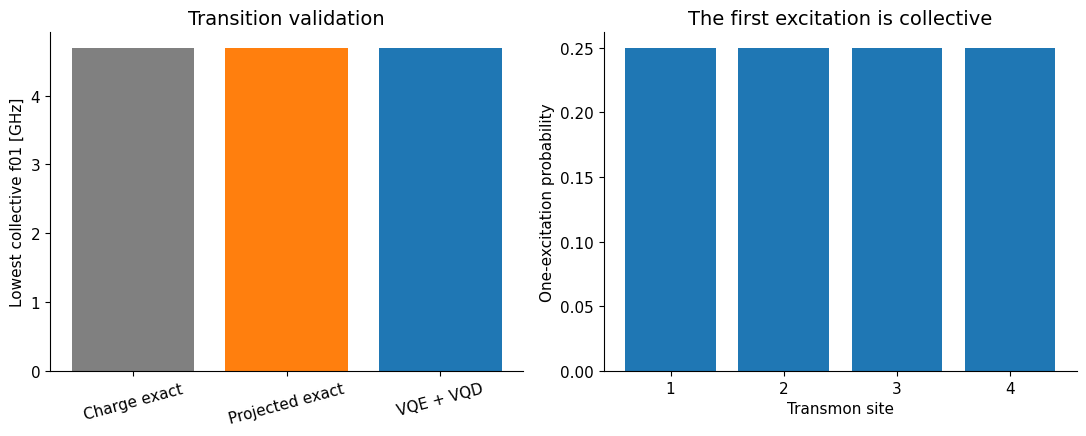

In [12]:
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
axes[0].bar(
    ["Charge exact","Projected exact","VQE + VQD"],
    [f01_charge,f01_projected,f01_vqd],
    color=["gray","tab:orange","tab:blue"],
)
axes[0].set(ylabel="Lowest collective f01 [GHz]",title="Transition validation")
axes[0].tick_params(axis="x",rotation=15)
axes[1].bar(np.arange(1,5),excited_run["state"][one_excitation]**2)
axes[1].set(xlabel="Transmon site",ylabel="One-excitation probability",
            title="The first excitation is collective",xticks=np.arange(1,5))
show_figure(fig,"02_transition_and_collective_state")

## Results and limitations

The saved outputs were executed with the defaults above. Rerunning after changing inputs updates the code outputs and figures; the numerical example in this Markdown table describes the saved default run.

| Quantity | Saved default result |
|---|---:|
| Inferred effective capacitance per site | 93.31249669 fF |
| $E_C/h$ per site | 0.20758451 GHz |
| $E_J/h$ per site | 16.34615128 GHz |
| Isolated-transmon quantum $f_{01}$ | 4.99328164 GHz |
| Full charge collective $f_{01}$ at $N=7$ | 4.683236766541 GHz |
| Four-level projected exact collective $f_{01}$ | 4.683249295297 GHz |
| VQE/VQD collective $f_{01}$ | 4.683249295299 GHz |
| Absolute transition error versus full charge at $N=7$ | 12.529 kHz |
| Absolute transition error versus the projected model | approximately 0.0014 Hz |
| Squared ground/excited overlap | $2.06\times10^{-13}$ |
| Baseline Qiskit VQE plus VQD optimization time | approximately 16.2 s on the test machine |

The excellent projected-model agreement is a noiseless numerical result. Its precision is much greater than the accuracy warranted by the assumed device parameters. The transition differs from the isolated value because of the illustrative charge couplings; it should not be forced to 5 GHz by changing the optimizer.

The result depends separately on charge cutoff, local-level projection, ansatz, optimizer and physical-model calibration. The comparison sections below measures the first four and explores capacitance/coupling sensitivity. Predicting the fabricated circuit also requires reliable couplings, a consistent capacitance model, and any relevant interconnect modes. Gate noise, finite shots, dissipation and drive matrix elements are not simulated. Dense and sparse classical solvers are appropriate baselines for this small system; no computational advantage is established.

## Parameter comparisons for the project presentation

### Run the controlled optimizer and initialization study

This section repeats the mapped problem and its VQE/VQD pipeline for **3 optimizers × 4 initializations × 3 seeds = 36 two-state runs**. Each state has the same configurable cap of 600 energy evaluations. The job order is shuffled with a fixed seed to reduce a systematic ordering bias in timings.

Use the verified faster statevector kernel consistently for these repetitions. Exact diagonalization, which validates the result, is excluded from the recorded optimizer time. L-BFGS-B has access to analytic classical gradients; the gradient-free methods do not. Interpret the comparison as performance of these complete local-simulator configurations, rather than an equal-resource hardware benchmark.

Records contain separate ground/excited errors, transition errors, fidelities, overlaps, energy/gradient calls, runtime and convergence flags. A small transition error alone is insufficient because the two energy errors may cancel. Expect completion of 36 pipelines; some methods exhaust their budget.

In [13]:
def run_pipeline(method, kind, run_seed, budget, masks=full_masks,
                 matrix=A, reference=None, penalty=beta):
    """Optimize both states and independently assess their transition."""
    g = optimize_state(0, method, kind, run_seed, budget, masks=masks,
                       matrix_physical=matrix)
    ex = optimize_state(
        1, method, kind, run_seed+1000, budget, masks=masks,
        ground_state=g["state"], beta=penalty, matrix_physical=matrix,
        reference_matrix=reference,
    )
    values, vectors = np.linalg.eigh(matrix)
    f_reference = float(values[1]-values[0])
    transition = ex["energy"]-g["energy"]
    overlap = float((g["state"] @ ex["state"])**2)
    first_subspace = vectors[:, np.abs(values-values[1]) < 1e-8]
    return dict(
        optimizer=method, initialization=kind, seed=int(run_seed),
        transition_ghz=transition,
        projected_transition_ghz=f_reference,
        projected_error_khz=abs(transition-f_reference)*1e6,
        charge_error_khz=abs(transition-f01_charge)*1e6 if matrix is A else np.nan,
        ground_error_khz=abs(g["energy"]-values[0])*1e6,
        excited_error_khz=abs(ex["energy"]-values[1])*1e6,
        overlap=overlap, ground_fidelity=float((vectors[:,0] @ g["state"])**2),
        excited_fidelity=float(np.sum((first_subspace.T @ ex["state"])**2)),
        seconds=g["seconds"]+ex["seconds"], energy_calls=g["nfev"]+ex["nfev"],
        gradient_calls=g["njev"]+ex["njev"],
        converged=bool(g["converged"] and ex["converged"]),
        ground=g, excited=ex,
    )


methods = ["COBYLA","Powell","L-BFGS-B"]
initializations = ["Reference","Perturbative","Small random","Uniform random"]
colors = {"COBYLA":"#0072B2","Powell":"#D55E00","L-BFGS-B":"#009E73"}
comparison_runs = []
jobs = [(m,k,s) for m in methods for k in initializations for s in study_seeds]
for job_index in np.random.default_rng(seed).permutation(len(jobs)):
    method,kind,run_seed = jobs[job_index]
    comparison_runs.append(run_pipeline(method,kind,run_seed,study_budget))
print(f"Completed {len(comparison_runs)} two-state comparison pipelines.")


def selected(method=None, kind=None):
    return [r for r in comparison_runs
            if (method is None or r["optimizer"]==method)
            and (kind is None or r["initialization"]==kind)]


def incumbent_transition_trace(record):
    """Select using deflated cost, then assess physical transition error."""
    costs = record["excited"]["cost"]
    indices = []
    best = 0
    for index in range(len(costs)):
        if costs[index] < costs[best]:
            best = index
        indices.append(best)
    e1 = record["excited"]["energy_trace"][indices]
    trace = abs(e1-record["ground"]["energy"]-f01_projected)*1e6
    return np.pad(trace,(0,study_budget-len(trace)),mode="edge")

Completed 36 two-state comparison pipelines.


### Figure 3 — Initial angles and optimizer choice

For each initialization, plot median transition error against the **projected** exact reference versus VQD energy evaluations. Shading gives the interquartile range of three seeds. These are descriptive repeat statistics, not confidence intervals; identical zero-angle starts repeat the same deterministic calculation.

Each trace uses the incumbent selected by lowest **deflated cost**, then calculates its physical transition error using the final ground energy. Selection never uses the exact validation answer. Runs that terminate early are extended horizontally to show their final value through the common budget; no extra evaluations are performed. The dashed line is the chosen 50 kHz target, and the tiny plotting floor only permits logarithmic display.

Expect perturbative/reference starts with analytic-gradient L-BFGS-B to outperform broad random starts on this model. Broad random angles can leave large residual errors even after the budget is spent. This supports using physics-informed starting states; it is not a universal ranking of optimizers.

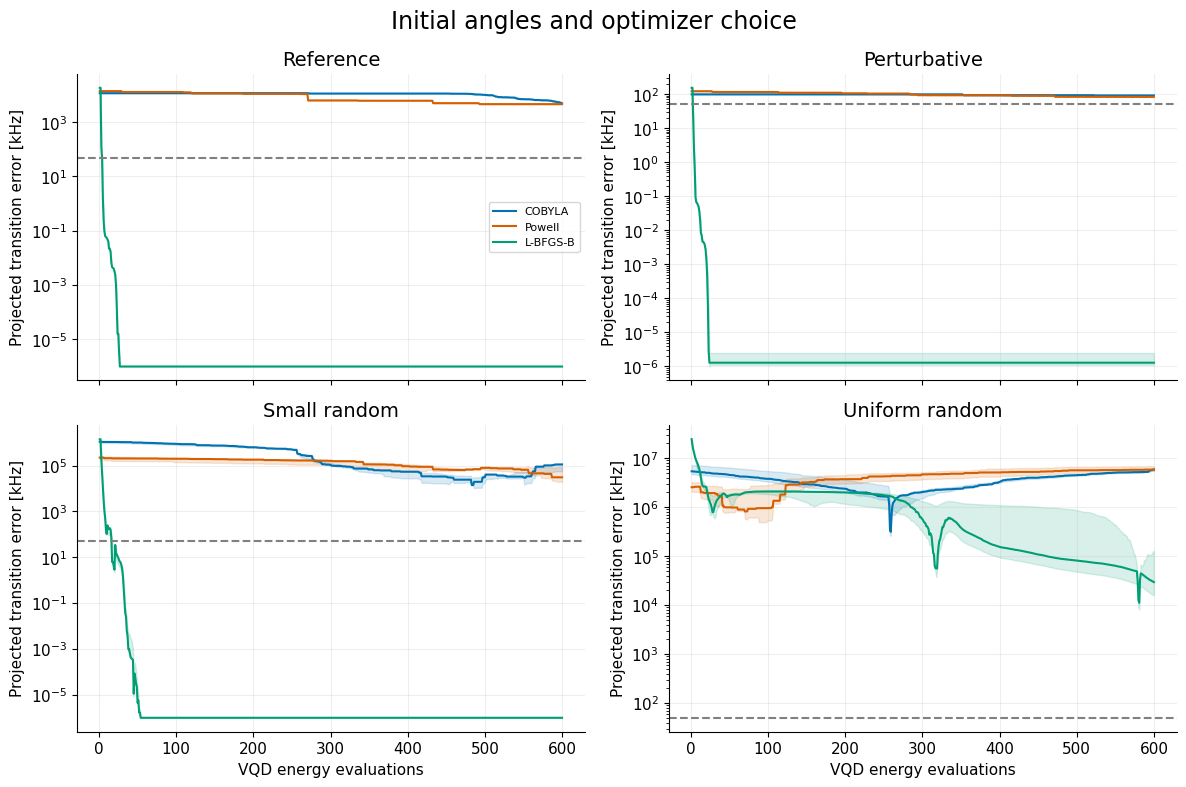

In [14]:
fig, axes = plt.subplots(2,2,figsize=(12,8),sharex=True)
for ax,kind in zip(axes.ravel(),initializations):
    for method in methods:
        traces = np.array([incumbent_transition_trace(r) for r in selected(method,kind)])
        low,median,high = np.quantile(traces,[0.25,0.5,0.75],axis=0)
        x = np.arange(1,study_budget+1)
        ax.plot(x,np.maximum(median,plot_floor),label=method,color=colors[method])
        ax.fill_between(x,np.maximum(low,plot_floor),np.maximum(high,plot_floor),
                        alpha=0.15,color=colors[method])
    ax.axhline(transition_target_khz,ls="--",color="gray")
    ax.set(title=kind,yscale="log",ylabel="Projected transition error [kHz]")
    ax.grid(alpha=0.2)
axes[1,0].set_xlabel("VQD energy evaluations")
axes[1,1].set_xlabel("VQD energy evaluations")
axes[0,0].legend(fontsize=8)
fig.suptitle("Initial angles and optimizer choice",fontsize=17)
show_figure(fig,"03_initial_angles_and_optimizers")

### Figure 4 — Final transition accuracy across configurations

The heatmap reports median absolute transition error against the **full charge model at $N=7$**, in kHz. This includes the local-level projection error, whereas Figure 3 isolates projected-model optimization error. Hence a roughly 13 kHz floor here is consistent with near-zero optimizer error there.

Read each column together with the runtime plot. The gradient-free methods are less accurate within this particular 600-call budget; a short runtime does not imply a successful solve. Expect L-BFGS-B with reference, perturbative or small-random starts to approach the projection floor, while uniform-random starts are unreliable.

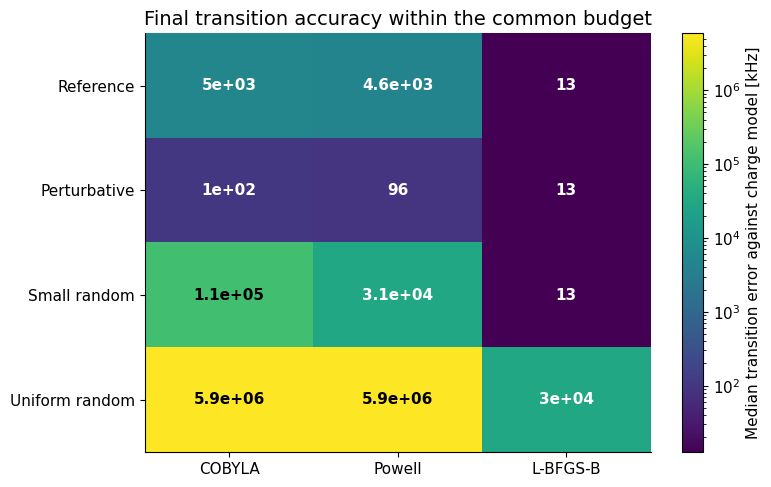

In [15]:
errors = np.array([[np.median([r["charge_error_khz"] for r in selected(m,k)])
                    for m in methods] for k in initializations])
fig,ax=plt.subplots(figsize=(8,5))
normalizer=LogNorm(vmin=max(errors.min(),plot_floor),vmax=max(errors.max(),plot_floor*10))
image=ax.imshow(np.maximum(errors,plot_floor),aspect="auto",norm=normalizer,cmap="viridis")
ax.set_xticks(range(len(methods)),methods)
ax.set_yticks(range(len(initializations)),initializations)
for i in range(len(initializations)):
    for j in range(len(methods)):
        ax.text(j,i,f"{errors[i,j]:.2g}",ha="center",va="center",
                color="black" if normalizer(errors[i,j])>.65 else "white",weight="bold")
fig.colorbar(image,ax=ax,label="Median transition error against charge model [kHz]")
ax.set_title("Final transition accuracy within the common budget")
show_figure(fig,"04_transition_accuracy")

### Figure 5 — Optimizer runtime and energy calls

Show the two-state local optimizer time and total energy calls, pooling the four initializations and three seeds for each optimizer. Points are individual runs; boxes summarize this deliberately mixed set of starts. The cap allows at most 1,200 energy calls across the two states.

The L-BFGS-B time includes its analytic-gradient work. A gradient call is not a hardware-free operation; `gradient_calls` is recorded separately. This graph shows practical simulator effort and sensitivity to starting conditions. Read it with Figures 3 and 4 rather than interpreting all returned states as equally accurate.

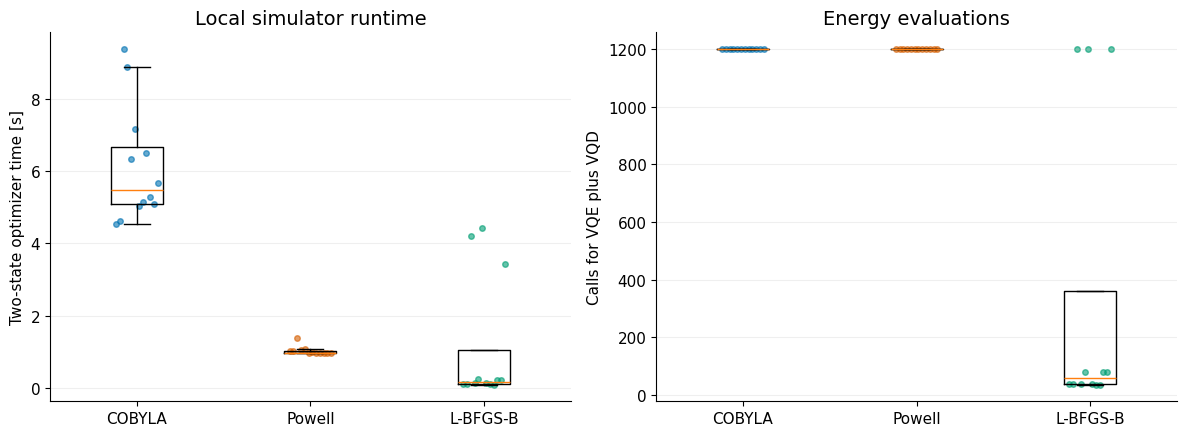

In [16]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,field,title,ylabel in [
    (axes[0],"seconds","Local simulator runtime","Two-state optimizer time [s]"),
    (axes[1],"energy_calls","Energy evaluations","Calls for VQE plus VQD"),
]:
    values=[[r[field] for r in selected(m)] for m in methods]
    ax.boxplot(values,tick_labels=methods,showfliers=False)
    for k,v in enumerate(values):
        ax.scatter(k+1+np.linspace(-.12,.12,len(v)),v,
                   color=colors[methods[k]],s=16,alpha=.6)
    ax.set(title=title,ylabel=ylabel)
    ax.grid(axis="y",alpha=.2)
show_figure(fig,"05_optimizer_runtime_and_calls")

### Figure 6 — Runtime versus classical diagonalization

Compare solvers on the **same 256-state projected Hamiltonian**. Dense and sparse classical solvers request its two lowest eigenvalues and report medians of seven repeats. Variational bars use perturbative starts, with three-repeat medians for the fast kernel and one separately timed baseline Qiskit run. Both variational states are included.

Common Hamiltonian construction, reference preparation, compilation and validation are excluded from solve timings. The sparse conversion is included in its timed call; dense methods already receive `A`. These timings characterize implementations on this computer, not intrinsic algorithmic complexity. The full charge reference has a different dimension and is timed separately in Figure 7.

Expect classical diagonalization to be much faster here. COBYLA and Powell also have larger errors within the chosen budget, so these bars are **not a time-to-equal-accuracy comparison**. Figure 4 supplies the accompanying accuracy check. No QPU speedup or hardware runtime is inferred.

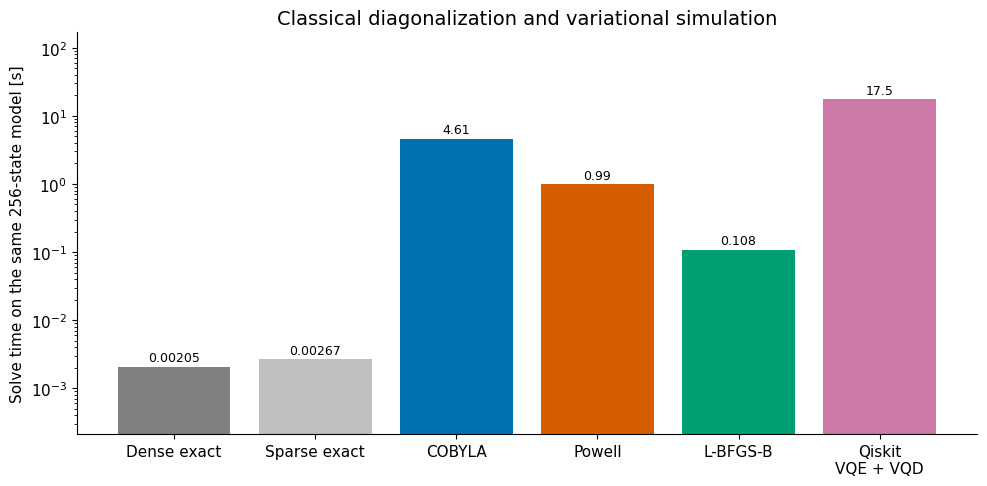

In [17]:
# Compare identical projected Hamiltonians, with shared model construction excluded.
dense_seconds=[]
sparse_seconds=[]
for repeat in range(7):
    started=perf_counter()
    dense_values=eigh(A,subset_by_index=[0,1],eigvals_only=True)
    dense_seconds.append(perf_counter()-started)
    started=perf_counter()
    sparse_values=eigsh(sp.csr_matrix(A),k=2,which="SA",tol=1e-11,
                        return_eigenvectors=False,
                        v0=np.random.default_rng(seed+repeat).normal(size=len(A)))
    sparse_seconds.append(perf_counter()-started)
assert np.allclose(np.sort(sparse_values),dense_values,atol=1e-8)
best_local_times = [
    np.median([r["seconds"] for r in selected(m,"Perturbative")]) for m in methods
]
names=["Dense exact","Sparse exact",*methods,"Qiskit\nVQE + VQD"]
times=[np.median(dense_seconds),np.median(sparse_seconds),*best_local_times,
       ground_run["seconds"]+excited_run["seconds"]]
fig,ax=plt.subplots(figsize=(10,5))
bars=ax.bar(names,times,color=["gray","silver",*[colors[m] for m in methods],"#CC79A7"])
ax.set(yscale="log",ylabel="Solve time on the same 256-state model [s]",
       title="Classical diagonalization and variational simulation")
for bar,value in zip(bars,times):
    ax.annotate(f"{value:.3g}",(bar.get_x()+bar.get_width()/2,value),
                xytext=(0,4),textcoords="offset points",ha="center",fontsize=9)
ax.margins(y=.25)
show_figure(fig,"06_classical_runtime_comparison")

### Figure 7 — Charge truncation: accuracy versus classical cost

Repeat the full charge solve for increasing cutoffs while holding the physical parameters fixed. A cutoff $N$ retains $2N+1$ Cooper-pair charge values **per island**, so the four-island dimension is $(2N+1)^4$.

The first panel compares the transition to the largest tested cutoff, $N=8$ with the defaults; that reference point itself is omitted from the log error curve. The second shows median sparse solve time. Expect a shift of about 4.27 kHz from $N=7$ to $N=8$, below the 50 kHz target, while $N=6$ remains above the target.

This supports $N=7$ for this transition and these parameters. A successive-cutoff difference is an empirical convergence check, not a rigorous bound on the infinite-basis error. Recheck it after changing circuit parameters. Higher levels and stronger charge fluctuations can require a larger cutoff.

/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_67278/477346295.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  sp.diags(n, format="csr"),


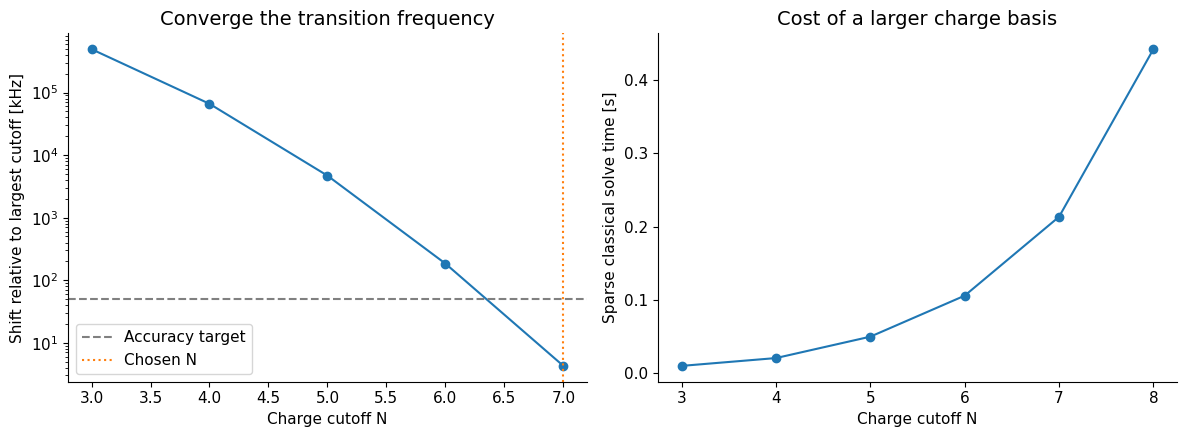

In [18]:
cutoff_records=[]
for cutoff in sorted(set([3,4,5,6,7,8,N])):
    result=charge_reference(cutoff,repeats=3)
    e0,e1=result["energies"]
    cutoff_records.append(dict(
        cutoff=cutoff,dimension=(2*cutoff+1)**4,
        transition_ghz=float(e1-e0),solve_seconds=float(np.median(result["seconds"])),
        build_seconds=result["build_seconds"],
    ))
converged_charge_frequency=cutoff_records[-1]["transition_ghz"]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
x=[r["cutoff"] for r in cutoff_records]
frequency_errors=[abs(r["transition_ghz"]-converged_charge_frequency)*1e6
                  for r in cutoff_records]
axes[0].semilogy(x[:-1],np.maximum(frequency_errors[:-1],plot_floor),"o-")
axes[0].axhline(transition_target_khz,ls="--",color="gray",label="Accuracy target")
axes[0].axvline(N,ls=":",color="tab:orange",label="Chosen N")
axes[0].set(xlabel="Charge cutoff N",ylabel="Shift relative to largest cutoff [kHz]",
            title="Converge the transition frequency")
axes[0].legend()
axes[1].plot(x,[r["solve_seconds"] for r in cutoff_records],"o-")
axes[1].set(xlabel="Charge cutoff N",ylabel="Sparse classical solve time [s]",
            title="Cost of a larger charge basis")
show_figure(fig,"07_charge_cutoff")

### Figure 8 — Number of retained levels per transmon

Compare exact projected transitions with 2, 4 and 6 isolated-transmon levels against the full charge reference at the same $N=7$. This isolates local-level projection from optimizer performance.

Expect the two-level approximation to miss the target, four levels to give about 12.53 kHz error, and six levels to reduce it further. Four levels give an economical power-of-two encoding on eight qubits. The six-level comparison is classical only; it does not silently reuse the eight-qubit circuit or require a padding prescription.

These studies vary one approximation at a time. Their absolute shifts need not add with the same sign or represent independent statistical uncertainties.

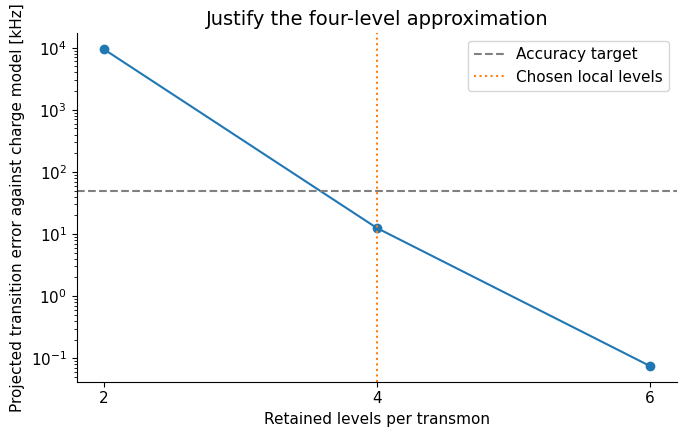

In [19]:
level_records=[]
for count in (2,4,6):
    q_projected=[sp.csr_matrix(v[:,:count].T @ q @ v[:,:count])
                 for v,q in zip(local_v,local_q)]
    matrix=build_hamiltonian([sp.diags(e[:count]) for e in local_e],q_projected).toarray()
    values=eigh(matrix,subset_by_index=[0,1],eigvals_only=True)
    level_records.append(dict(
        local_levels=count,dimension=count**4,transition_ghz=float(values[1]-values[0]),
        charge_error_khz=abs(values[1]-values[0]-f01_charge)*1e6,
    ))
fig,ax=plt.subplots(figsize=(7,4.5))
ax.semilogy([r["local_levels"] for r in level_records],
            [max(r["charge_error_khz"],plot_floor) for r in level_records],"o-")
ax.axhline(transition_target_khz,ls="--",color="gray",label="Accuracy target")
ax.axvline(local_levels,ls=":",color="tab:orange",label="Chosen local levels")
ax.set(xlabel="Retained levels per transmon",
       ylabel="Projected transition error against charge model [kHz]",
       title="Justify the four-level approximation",xticks=[2,4,6])
ax.legend()
show_figure(fig,"08_local_level_truncation")

### Figure 9 — Ansatz accuracy versus compiled circuit cost

Compare the restricted 66-angle pair-rotation pool with the 255-angle full pool, using the same perturbative L-BFGS-B configuration. Show absolute transition error against the full charge reference and compiled excited-circuit CX count.

Expect the full pool to meet the target at higher circuit cost. The smaller pool is cheaper but leaves a significant residual with this configuration. The comparison tests these two circuit families and optimization runs; it is not a proof that every smaller circuit is inadequate. Counts depend on the chosen target and transpiler settings, and a hundreds-of-CX circuit is demanding for noisy hardware.

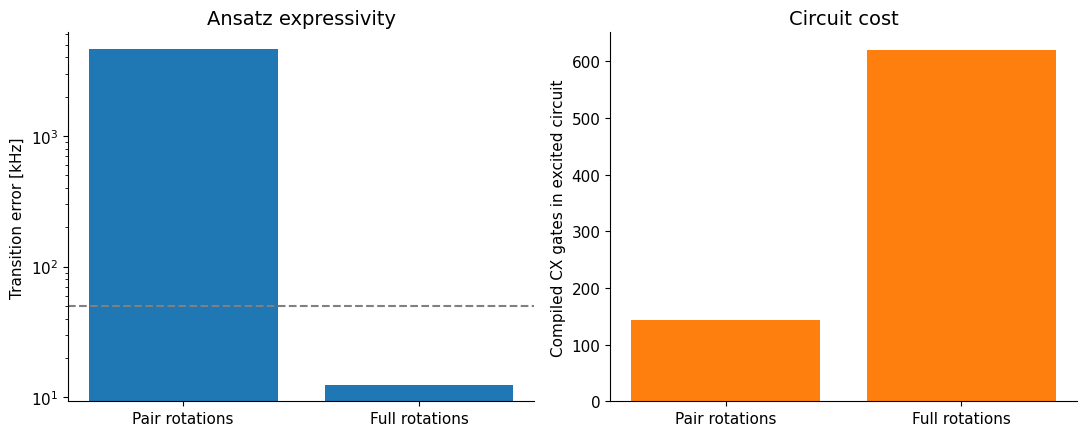

In [20]:
ansatz_records=[]
pair_ground=make_ansatz(pair_masks,ground_reference_circuit,"pair_g")
pair_excited=make_ansatz(pair_masks,excited_reference_circuit,"pair_e")
for name,masks,circuit in (
    ("Pair rotations",pair_masks,pair_excited),
    ("Full rotations",full_masks,excited_ansatz),
):
    run=run_pipeline("L-BFGS-B","Perturbative",seed,baseline_maxfun,masks=masks)
    compiled=pm.run(circuit)
    ansatz_records.append(dict(
        ansatz=name,parameters=len(masks),cx_gates=int(compiled.count_ops().get("cx",0)),
        transition_error_khz=run["charge_error_khz"],seconds=run["seconds"],
    ))
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
names=[r["ansatz"] for r in ansatz_records]
axes[0].bar(names,[r["transition_error_khz"] for r in ansatz_records])
axes[0].set(yscale="log",ylabel="Transition error [kHz]",title="Ansatz expressivity")
axes[0].axhline(transition_target_khz,ls="--",color="gray")
axes[1].bar(names,[r["cx_gates"] for r in ansatz_records],color="tab:orange")
axes[1].set(ylabel="Compiled CX gates in excited circuit",title="Circuit cost")
show_figure(fig,"09_ansatz_accuracy_and_depth")

### Figure 10 — VQD penalty strength and ground-state contamination

Vary the multiplier on the conservative baseline $\beta$ while keeping the optimized ground state fixed. A small random excited-state start permits both parity sectors, making collapse visible rather than protecting the answer by construction.

Plot the returned **physical** transition and squared ground overlap. Expect small penalties to rediscover the ground state, producing a transition near zero and overlap near one. A sufficiently large penalty recovers the first excited state and suppresses overlap. The theoretical threshold applies to an exact ground reference; these numerical checks test the approximate reference actually used.

A larger penalty is not automatically better: it can worsen conditioning and would amplify overlap-estimation noise on hardware. The noiseless scan justifies a sufficient, moderate default for this model.

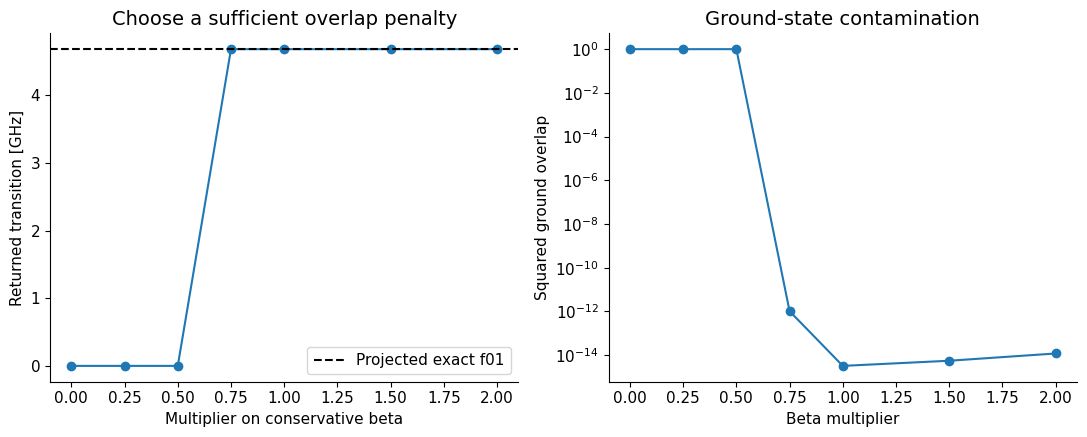

In [21]:
penalty_records=[]
for factor in (0,0.25,0.5,0.75,1,1.5,2):
    trial=optimize_state(
        1,"L-BFGS-B","Small random",seed+400,baseline_maxfun,
        ground_state=ground_run["state"],beta=factor*beta,
    )
    penalty_records.append(dict(
        beta_factor=factor,beta_ghz=factor*beta,
        transition_ghz=trial["energy"]-ground_run["energy"],
        overlap=float((ground_run["state"]@trial["state"])**2),
    ))
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
x=[r["beta_factor"] for r in penalty_records]
axes[0].plot(x,[r["transition_ghz"] for r in penalty_records],"o-")
axes[0].axhline(f01_projected,ls="--",color="black",label="Projected exact f01")
axes[0].set(xlabel="Multiplier on conservative beta",
            ylabel="Returned transition [GHz]",title="Choose a sufficient overlap penalty")
axes[0].legend()
axes[1].semilogy(x,np.maximum([r["overlap"] for r in penalty_records],1e-18),"o-")
axes[1].set(xlabel="Beta multiplier",ylabel="Squared ground overlap",
            title="Ground-state contamination")
show_figure(fig,"10_deflation_penalty")

### Figure 11 — Coupling strength and the collective transition

Scale all illustrative ring coefficients together, keeping local parameters fixed. Rebuild the excited reference from the corresponding one-excitation block at every point, then compare VQE/VQD with the projected exact transition.

Expect the zero-coupling transition to approach the isolated value near 4.99328 GHz, and the lowest collective transition to decrease as these positive ring couplings grow. The dependence is specific to this graph and sign convention. At zero coupling the first excited level is degenerate; its energy is meaningful without assigning a unique eigenvector.

This graph explains why accurate optimization does not force a coupled-system transition to equal the isolated value. The assumed coefficients are not yet calibrated device parameters. Comparisons here share the four-level projection; they do not revalidate charge/projection convergence at every coupling.

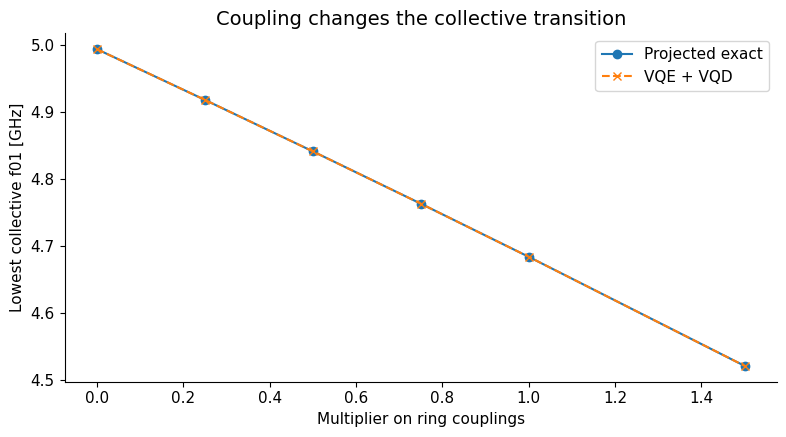

In [22]:
def reference_for_matrix(matrix):
    """Prepare the lowest state in its four-dimensional one-excitation block."""
    _,vectors=np.linalg.eigh(matrix[np.ix_(one_excitation,one_excitation)])
    weights=vectors[:,0].copy()
    if weights[0]<0:
        weights*=-1
    circuit=QuantumCircuit(num_qubits)
    circuit.x(0)
    for site in range(1,4):
        remaining=np.sqrt(weights[0]**2+np.sum(weights[site+1:]**2))
        angle=-2*np.arctan2(weights[site],remaining)
        a,b=0,2*site
        circuit.cx(a,b);circuit.cry(angle,b,a);circuit.cx(a,b)
    return Operator(circuit).data.real


A_local=build_hamiltonian(
    [sp.diags(e[:4]) for e in local_e],
    [sp.csr_matrix(q.shape) for q in projected_q],
).toarray()
A_coupling=A-A_local
coupling_records=[]
for factor in (0,0.25,0.5,0.75,1,1.5):
    matrix=A_local+factor*A_coupling
    reference=reference_for_matrix(matrix)
    run=run_pipeline("L-BFGS-B","Perturbative",seed,baseline_maxfun,
                      matrix=matrix,reference=reference)
    coupling_records.append(dict(
        coupling_factor=factor,projected_transition_ghz=run["projected_transition_ghz"],
        vqd_transition_ghz=run["transition_ghz"],
        optimizer_error_khz=run["projected_error_khz"],
    ))
fig,ax=plt.subplots(figsize=(8,4.5))
x=[r["coupling_factor"] for r in coupling_records]
ax.plot(x,[r["projected_transition_ghz"] for r in coupling_records],"o-",label="Projected exact")
ax.plot(x,[r["vqd_transition_ghz"] for r in coupling_records],"x--",label="VQE + VQD")
ax.set(xlabel="Multiplier on ring couplings",ylabel="Lowest collective f01 [GHz]",
       title="Coupling changes the collective transition")
ax.legend()
show_figure(fig,"11_coupling_and_transition")

### Figure 12 — Effective-capacitance sensitivity and numerical error budget

The first panel varies the **isolated single-transmon** effective capacitance at fixed $E_J$ inferred from 10 nH. At each point, it exactly diagonalizes the charge Hamiltonian and plots its quantum transition. The vertical line marks the capacitance inferred from the supplied linear frequency. This is a parameter-sensitivity illustration, not an uncertainty distribution or a new fit of the four-transmon model.

The second panel separates three frequency scales: the $N=7\to8$ charge-cutoff shift, the four-level projection shift at $N=7$, and the baseline VQE/VQD error against that projected matrix. Expect roughly 4.27 kHz, 12.53 kHz and 0.0014 Hz respectively. Projection dominates these numerical errors; uncertain physical capacitances and couplings can dominate all of them.

The bars are absolute shifts between different calculations. They are not independent random errors and should not automatically be summed in quadrature. The horizontal line is the configurable 50 kHz target.

/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_67278/477346295.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  sp.diags(n, format="csr"),


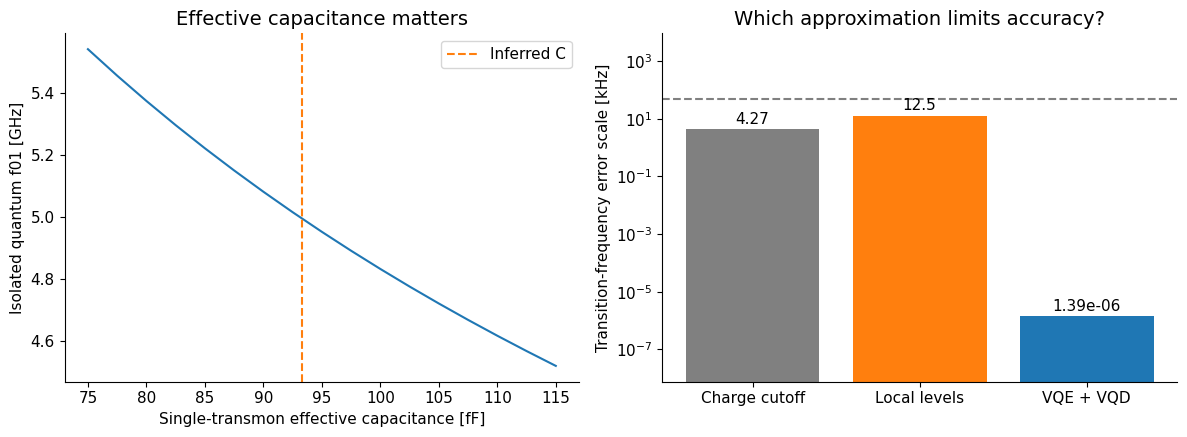

In [23]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
capacitances_ff=np.linspace(75,115,17)
cap_frequencies=[]
for cap_ff in capacitances_ff:
    ec=electron_charge**2/(2*cap_ff*1e-15*planck_h)/1e9
    h_local,_=local_hamiltonian(ec,E_J[0],N)
    values=np.linalg.eigvalsh(h_local.toarray())
    cap_frequencies.append(values[1]-values[0])
axes[0].plot(capacitances_ff,cap_frequencies)
axes[0].axvline(C_effective[0]*1e15,ls="--",color="tab:orange",label="Inferred C")
axes[0].set(xlabel="Single-transmon effective capacitance [fF]",
            ylabel="Isolated quantum f01 [GHz]",title="Effective capacitance matters")
axes[0].legend()
cutoff_shift=abs(converged_charge_frequency-f01_charge)*1e6
projection_shift=abs(f01_projected-f01_charge)*1e6
variational_shift=abs(f01_vqd-f01_projected)*1e6
values=[max(v,plot_floor) for v in (cutoff_shift,projection_shift,variational_shift)]
bars=axes[1].bar(["Charge cutoff","Local levels","VQE + VQD"],values,
                 color=["gray","tab:orange","tab:blue"])
axes[1].set(yscale="log",ylabel="Transition-frequency error scale [kHz]",
            title="Which approximation limits accuracy?")
for bar,value in zip(bars,values):
    axes[1].annotate(f"{value:.3g}",(bar.get_x()+bar.get_width()/2,value),
                     xytext=(0,4),textcoords="offset points",ha="center")
axes[1].axhline(transition_target_khz,ls="--",color="gray")
axes[1].margins(y=.3)
show_figure(fig,"12_capacitance_and_error_budget")

### Reproducible results and optional exports

Print the model assumptions, calculated parameters, transition frequencies, error scales, repeat seeds, budgets and timing scope. The stored comparison records retain convergence and fidelity information for more detailed inspection.

With both saving flags left `False`, this cell creates no data or figure export folders. Enabling `SAVE_DATA` explicitly writes scalar comparison tables and a summary; enabling `SAVE_FIGURES` explicitly writes figures when their plotting cells are rerun. Saving the notebook itself preserves its displayed outputs in the usual Jupyter way.

In [24]:
summary={
    "circuit_assumption":"Four identical copies of the supplied isolated-transmon parameters",
    "couplings":"Illustrative 0.10 GHz charge coefficients on a ring",
    "effective_capacitance_ff":(C_effective*1e15).tolist(),
    "charge_cutoff":N,"local_levels":local_levels,"qubits":num_qubits,
    "charge_f01_ghz":f01_charge,"projected_f01_ghz":f01_projected,
    "vqd_f01_ghz":f01_vqd,"charge_cutoff_shift_khz":cutoff_shift,
    "local_projection_shift_khz":projection_shift,
    "variational_shift_khz":variational_shift,
    "comparison_pipelines":len(comparison_runs),"repeat_seeds":study_seeds,
    "energy_budget_per_state":study_budget,"target_khz":transition_target_khz,
    "figure_count":len(figure_names),"python":platform.python_version(),
    "timing_scope":"Local simulation with model construction excluded",
    "gradient_scope":"Exact classical statevector adjoint gradients for L-BFGS-B",
}
print(json.dumps(summary,indent=2))
if SAVE_DATA:
    folder=Path("four_transmon_vqd_data")
    folder.mkdir(exist_ok=True)
    for filename,records in (
        ("optimizer_comparisons.csv",comparison_runs),("charge_cutoff.csv",cutoff_records),
        ("local_levels.csv",level_records),("ansatz.csv",ansatz_records),
        ("penalty.csv",penalty_records),("coupling.csv",coupling_records),
    ):
        keys=[k for k,v in records[0].items() if isinstance(v,(str,int,float,bool,np.integer,np.floating))]
        with open(folder/filename,"w",newline="") as handle:
            writer=csv.DictWriter(handle,fieldnames=keys,extrasaction="ignore")
            writer.writeheader();writer.writerows(records)
    (folder/"summary.json").write_text(json.dumps(summary,indent=2))

{
  "circuit_assumption": "Four identical copies of the supplied isolated-transmon parameters",
  "couplings": "Illustrative 0.10 GHz charge coefficients on a ring",
  "effective_capacitance_ff": [
    93.31249669455167,
    93.31249669455167,
    93.31249669455167,
    93.31249669455167
  ],
  "charge_cutoff": 7,
  "local_levels": 4,
  "qubits": 8,
  "charge_f01_ghz": 4.683236766540752,
  "projected_f01_ghz": 4.683249295297465,
  "vqd_f01_ghz": 4.68324929529885,
  "charge_cutoff_shift_khz": 4.26574724343709,
  "local_projection_shift_khz": 12.528756712981703,
  "variational_shift_khz": 1.3855583347321954e-06,
  "comparison_pipelines": 36,
  "repeat_seeds": [
    11,
    22,
    33
  ],
  "energy_budget_per_state": 600,
  "target_khz": 50.0,
  "figure_count": 12,
  "python": "3.14.0",
  "timing_scope": "Local simulation with model construction excluded",
  "gradient_scope": "Exact classical statevector adjoint gradients for L-BFGS-B"
}


## Results, parameter choices and meeting discussion

For the saved default run:

- **Physical inputs:** the common 10 nH and 5.21015 GHz linear inputs imply 93.31 fF and $E_J/E_C\simeq78.74$. They describe the supplied isolated-circuit calibration; ring couplings remain illustrative.
- **Transition:** VQE/VQD gives $f_{01}=4.683249295299$ GHz. The full charge result at $N=7$ is 4.683236766541 GHz, giving **12.529 kHz absolute error**, principally from the local projection.
- **Charge cutoff:** $N=7$ gives a 4.27 kHz change relative to $N=8$. It meets the chosen 50 kHz transition target without the largest basis cost.
- **Local levels:** four levels per transmon give a 12.53 kHz projection shift. Two levels are insufficient for this target; six are more accurate but cost more classical resources and require a larger circuit encoding if used for VQD.
- **Initialization and optimizer:** the perturbative reference with analytic-gradient L-BFGS-B reaches the projection limit quickly in the ideal simulator. Broad random angles are less reliable. This result relies on classical gradient access and the selected budgets.
- **Ansatz and penalty:** the larger rotation pool reduces the residual at a substantial CX cost. A sufficient overlap penalty avoids ground-state collapse; monitor both physical energy and overlap.
- **Classical baseline:** two-eigenvalue classical solvers take about 2 ms on the 256-state model on the test machine, versus about 0.12 s for the fast warm-start L-BFGS-B pipeline and 16.2 s for the separate Qiskit baseline. These exclude common preparation and are implementation-specific. Some faster-returning configurations have not met the accuracy target.

**Suggested presentation order:** use Figures 12 and 11 to establish the physical model; Figures 7 and 8 to justify truncations; Figures 3 and 4 to justify initial angles and optimizer; Figures 9 and 10 to explain circuit/deflation choices; then Figures 1 and 2 for the validated result, and Figures 5 and 6 for runtime and classical comparison.

**Questions worth discussing with the team**

- Are the four local inductances/frequencies actually identical, and were the quoted frequencies linear isolated modes?
- Can the assumed ring coefficients be replaced with a capacitance-matrix-based model or independently extracted effective couplings without double counting local loading?
- Does the relevant drive couple to the lowest collective mode, or should additional excited states and transition matrix elements be calculated?
- Is 50 kHz the right project accuracy target once physical-parameter uncertainty is included?
- Which reductions in circuit depth preserve the required accuracy, and what changes once shot noise and gate errors are introduced?

The current implementation measures numerical accuracy for a noiseless effective model. It does not predict linewidths, relaxation times, finite-temperature populations or hardware performance. The extremely small projected-model optimization error is not comparable to experimental precision. Repeat the convergence studies after changing the physical model rather than assuming the default truncations remain adequate.